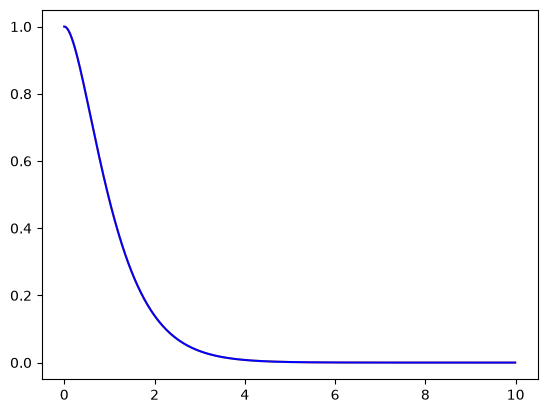

In [12]:
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import jax.random as jr
import jax.scipy.special as jss
import healpy as hp
import astropy as ap
from astropy.coordinates import SkyCoord
from dustmaps.edenhofer2023 import Edenhofer2023Query
import astropy.units as u
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)
logvar = jnp.log(1)
logscale = jnp.log(1)
lognu = jnp.log(1.5)
dx = 0.01
omegas = jnp.linspace(0, 100, 10000)
rs = jnp.arange(1000)*dx

def matern_spectral_density(omega, params, d=3):
    logvar, logscale, lognu = params
    nu = jnp.exp(lognu)
    log_norm = (logvar
                + d * jnp.log(2 * jnp.sqrt(jnp.pi))
                + jss.gammaln(nu + d / 2) - jss.gammaln(nu)
                + d * (logscale - 0.5 * jnp.log(2 * nu)))
    x = jnp.square(omega) * jnp.exp(2 * logscale - jnp.log(2.0) - lognu)
    return jnp.exp(log_norm - (nu + d / 2) * jnp.log1p(x))

def matern_32(r, variance=jnp.exp(logvar), scale=jnp.exp(logscale), jitter=1e-6):
    result = variance * (1 + jnp.sqrt(3)*r/scale)*jnp.exp(-1*jnp.sqrt(3)*r/scale);
    return jnp.where(r > 0, result, result * (1.0 + jitter))

def three_dim_hankel_transform(r, omegas, spectral_density):
    kernel = jnp.sinc(omegas[None, :] * r[:, None] / jnp.pi)       # sin(wr)/(wr)
    integrand = spectral_density[None, :] * omegas[None, :]**2 * kernel
    return jnp.trapezoid(integrand, omegas, axis=1) / (2 * jnp.pi**2)


spectral_density = matern_spectral_density(omegas, (logvar, logscale, lognu))
covariance_from_hankel = three_dim_hankel_transform(rs, omegas, spectral_density)

#plt.plot(omegas, spectral_density, color = "blue")
plt.plot(rs, covariance_from_hankel, color = "orange")
plt.plot(rs, matern_32(rs), color = "blue")


Cholesky ok: True


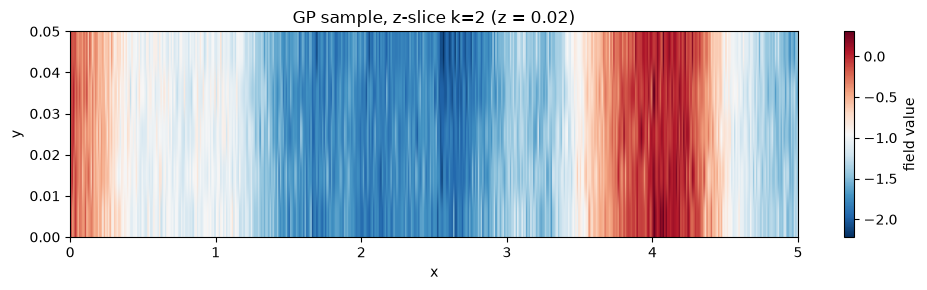

In [20]:
dim_1 = 500
dim_2 = 5
dim_3 = 5
N = dim_1*dim_2*dim_3
shape = (dim_1, dim_2, dim_3)
gp_grid = jnp.zeros(shape)
flat_gp_grid = jnp.arange(dim_1*dim_2*dim_3)
cov_matrix = jnp.zeros((dim_1*dim_2*dim_3, dim_1*dim_2*dim_3))

ix, iy, iz = jnp.meshgrid(jnp.arange(dim_1), jnp.arange(dim_2), jnp.arange(dim_3),
                          indexing="ij")
coords = dx * jnp.stack([ix.ravel(), iy.ravel(), iz.ravel()], axis=-1).astype(jnp.float64)  # (N, 3)

d2 = jnp.zeros((N, N))
for k in range(3):
    d2 = d2 + (coords[:, k, None] - coords[None, :, k])**2
dist = jnp.sqrt(d2)
del d2

cov_matrix = jnp.interp(dist, rs, covariance_from_hankel)
del dist

# sample
jitter = 1e-2
L = jnp.linalg.cholesky(cov_matrix + jitter * jnp.eye(N))
print("Cholesky ok:", not jnp.any(jnp.isnan(L)))

key = jr.PRNGKey(0)
sample = (L @ jr.normal(key, (N,))).reshape(shape)


k = 2                                  # which z-slice (0 to dim_3 - 1)
slice_2d = np.asarray(sample[:, :, k])  # shape (500, 5): axis 0 = x, axis 1 = y

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(
    slice_2d.T,                         # transpose so x runs horizontally
    origin="lower",
    aspect="auto",
    extent=[0, dim_1 * dx, 0, dim_2 * dx],
    cmap="RdBu_r",
)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"GP sample, z-slice k={k} (z = {k*dx:.2f})")
fig.colorbar(im, ax=ax, label="field value")
plt.tight_layout()
plt.show()